# Seasonal Patterns and Cancellation Analysis in Hotel Booking Data

## 1. Data Overview and Cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

HOTEL_COLORS = {'City Hotel': '#2E86AB', 'Resort Hotel': '#F26419'}
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_SHORT = [m[:3] for m in MONTHS]
ALPHA = 0.05

print('All libraries are ready to use.')

All libraries are ready to use.


In [2]:
raw = pd.read_csv('hotel_bookings.csv')

In [3]:
print(f'Rows    : {raw.shape[0]:,}')
print(f'Columns : {raw.shape[1]}')
raw.head()

Rows    : 119,390
Columns : 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,"119,390.00",0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,"119,390.00",104.01,106.86,0.00,18.00,69.00,160.00,737.00
arrival_date_year,"119,390.00","2,016.16",0.71,"2,015.00","2,016.00","2,016.00","2,017.00","2,017.00"
arrival_date_week_number,"119,390.00",27.17,13.61,1.00,16.00,28.00,38.00,53.00
arrival_date_day_of_month,"119,390.00",15.80,8.78,1.00,8.00,16.00,23.00,31.00
stays_in_weekend_nights,"119,390.00",0.93,1.00,0.00,0.00,1.00,2.00,19.00
stays_in_week_nights,"119,390.00",2.50,1.91,0.00,1.00,2.00,3.00,50.00
adults,"119,390.00",1.86,0.58,0.00,2.00,2.00,2.00,55.00
children,"119,386.00",0.10,0.40,0.00,0.00,0.00,0.00,10.00
babies,"119,390.00",0.01,0.10,0.00,0.00,0.00,0.00,10.00


In [6]:
raw.select_dtypes(exclude='number').describe().T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


**What the overview shows**

- The dataset has **119,390 bookings** and 32 columns; only 4 columns contain missing values: `company` (**94.3%**), `agent` (**13.7%**), `country` (**0.4%**) and `children` (4 rows).
- `is_canceled = 1` for **44,224 bookings (37.0%)**. This flag combines 43,017 `Canceled` and 1,207 `No-Show` records, so "cancellation" here means "the room was not used".
- `City Hotel` holds **66.5%** of bookings, `Resort Hotel` **33.5%**. `Online TA` is the largest market segment (**47.3%**), `Transient` the largest customer type (**75.1%**), and **12.2%** of bookings carry a `Non Refund` deposit.
- **31,994 rows (26.8%) are exact duplicates.** There is no booking ID, so identical rows can be different guests with the same profile.

In [7]:
missing_summary = (
    raw.isnull().sum().to_frame('missing_count')
    .assign(**{'missing_%': lambda x: x['missing_count'] / len(raw) * 100})
    .query('missing_count > 0')
    .sort_values('missing_count', ascending=False)
)

In [8]:
display(missing_summary)

,missing_count,missing_%
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [9]:
duplicate_rows = raw.duplicated().sum()
print(f'Duplicate rows : {duplicate_rows:,} ({duplicate_rows / len(raw) * 100:.1f}% of all rows)')

Duplicate rows : 31,994 (26.8% of all rows)


In [10]:
raw.nunique().sort_values()

hotel                                2
is_canceled                          2
is_repeated_guest                    2
arrival_date_year                    3
deposit_type                         3
reservation_status                   3
customer_type                        4
babies                               5
meal                                 5
distribution_channel                 5
children                             5
required_car_parking_spaces          5
total_of_special_requests            6
market_segment                       8
reserved_room_type                  10
arrival_date_month                  12
assigned_room_type                  12
adults                              14
previous_cancellations              15
stays_in_weekend_nights             17
booking_changes                     21
arrival_date_day_of_month           31
stays_in_week_nights                35
arrival_date_week_number            53
previous_bookings_not_canceled      73
days_in_waiting_list     

In [11]:
for column in ['hotel', 'market_segment', 'customer_type', 'deposit_type', 'reservation_status']:
    counts = raw[column].value_counts()
    summary = pd.DataFrame({'bookings': counts, 'share_%': counts / len(raw) * 100})
    print(f'--- {column} ---')
    display(summary)

--- hotel ---


,bookings,share_%
hotel,,
City Hotel,79330,66.45
Resort Hotel,40060,33.55


--- market_segment ---


,bookings,share_%
market_segment,,
Online TA,56477,47.30
Offline TA/TO,24219,20.29
Groups,19811,16.59
Direct,12606,10.56
Corporate,5295,4.44
Complementary,743,0.62
Aviation,237,0.20
Undefined,2,0.00


--- customer_type ---


,bookings,share_%
customer_type,,
Transient,89613,75.06
Transient-Party,25124,21.04
Contract,4076,3.41
Group,577,0.48


--- deposit_type ---


,bookings,share_%
deposit_type,,
No Deposit,104641,87.65
Non Refund,14587,12.22
Refundable,162,0.14


--- reservation_status ---


,bookings,share_%
reservation_status,,
Check-Out,75166,62.96
Canceled,43017,36.03
No-Show,1207,1.01


**Cleaning decisions (missing values and duplicates)**

- `country` - 488 rows (0.41%) filled with `'Unknown'`. The origin is missing, the booking itself is valid, so the rows stay in every count.
- `agent` - 16,340 rows (13.69%) filled with `0`; `company` - 112,593 rows (94.31%) filled with `0`. Real IDs start at 1 (`agent`) and 6 (`company`), so `0` works as a "no agent / no company" flag. It is never averaged or treated as a number. A 94% empty column is not imputed any further.
- `children` - 4 rows (0.003%) filled with `0`.
- **Duplicates are kept.** Without a booking ID, dropping them would delete real bookings. Instead, section 3 repeats the key rates without duplicates to show how sensitive the headline numbers are.

In [12]:
df = raw.copy()

In [13]:
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0).astype(int)
df['company'] = df['company'].fillna(0).astype(int)
df['children'] = df['children'].fillna(0).astype(int)

In [14]:

print('Missing values after filling:')
print(df[['country', 'agent', 'company', 'children']].isnull().sum().to_string())
print(f"\nBookings without an agent   (agent == 0)   : {(df['agent'] == 0).sum():,}")
print(f"Bookings without a company  (company == 0) : {(df['company'] == 0).sum():,}")
print(f"Bookings with country 'Unknown'            : {(df['country'] == 'Unknown').sum():,}")

Missing values after filling:
country     0
agent       0
company     0
children    0

Bookings without an agent   (agent == 0)   : 16,340
Bookings without a company  (company == 0) : 112,593
Bookings with country 'Unknown'            : 488


In [15]:
quality_checks = {
    'adr < 0 (negative rate)': (df['adr'] < 0).sum(),
    'adr == 0 (free / complimentary stays)': (df['adr'] == 0).sum(),
    'adr > 1,000 (extreme outlier)': (df['adr'] > 1000).sum(),
    'zero nights (no weekend + week nights)': ((df['stays_in_weekend_nights'] + df['stays_in_week_nights']) == 0).sum(),
    'zero guests (adults + children + babies = 0)': ((df['adults'] + df['children'] + df['babies']) == 0).sum(),
    "market_segment == 'Undefined'": (df['market_segment'] == 'Undefined').sum(),
}

In [16]:
quality_summary = (
    pd.Series(quality_checks).to_frame('rows')
    .assign(**{'share_%': lambda x: x['rows'] / len(df) * 100})
)
quality_summary

,rows,share_%
adr < 0 (negative rate),1,0.00
adr == 0 (free / complimentary stays),1959,1.64
"adr > 1,000 (extreme outlier)",1,0.00
zero nights (no weekend + week nights),715,0.60
zero guests (adults + children + babies = 0),180,0.15
market_segment == 'Undefined',2,0.00


**Cleaning decisions (odd values)**

- `adr == 0` in 1,959 rows (1.64%), mostly complimentary stays; `adr < 0` in 1 row; `adr = 5,400` in 1 row (a cancelled `City Hotel` booking). Zero-night (715 rows) and zero-guest (180 rows) bookings also exist.
- These are real booking records with real outcomes, so **all rows stay for demand and cancellation analysis**. Only the ADR and revenue analysis uses `adr_valid` rows (`0 < adr < 1,000`): **117,429 of 119,390 rows** (1.64% excluded).

In [17]:
month_number = {month: number for number, month in enumerate(MONTHS, start=1)}

df['arrival_date'] = pd.to_datetime(dict(
    year=df['arrival_date_year'],
    month=df['arrival_date_month'].map(month_number),
    day=df['arrival_date_day_of_month'],
))

In [18]:

df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['lead_time_bin'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, 180, 365, np.inf],
    labels=['0-7', '8-30', '31-90', '91-180', '181-365', '365+'],)

In [19]:
df['adr_valid'] = (df['adr'] > 0) & (df['adr'] < 1000)
df['room_revenue'] = df['adr'] * df['total_nights']

In [20]:

print(f"arrival_date min      : {df['arrival_date'].min().date()}")
print(f"arrival_date max      : {df['arrival_date'].max().date()}")
print(f"arrival_date NaT      : {df['arrival_date'].isnull().sum()}")
print(f"total_nights min/max  : {df['total_nights'].min()} / {df['total_nights'].max()}")
print(f"lead_time min/max     : {df['lead_time'].min()} / {df['lead_time'].max()}")
print(f"Rows used for ADR     : {df['adr_valid'].sum():,} of {len(df):,}")
df[['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date']].head()

arrival_date min      : 2015-07-01
arrival_date max      : 2017-08-31
arrival_date NaT      : 0
total_nights min/max  : 0 / 69
lead_time min/max     : 0 / 737
Rows used for ADR     : 117,429 of 119,390


,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


`arrival_date` is built from year, month name (mapped to a number) and day. Verification: range 2015-07-01 to 2017-08-31, **0 `NaT`**. Other derived columns: `total_nights`, `total_guests`, `lead_time_bin`, `adr_valid` and `room_revenue` (= `adr` x `total_nights`, a revenue proxy, not booked revenue).

In [21]:
coverage = df.groupby('arrival_date_year').agg(
    first_arrival=('arrival_date', 'min'),
    last_arrival=('arrival_date', 'max'),
    bookings=('hotel', 'size'),
)

In [22]:
coverage['months_covered'] = (
    df.groupby('arrival_date_year')['arrival_date'].apply(lambda s: s.dt.month.nunique())
)
display(coverage)

,first_arrival,last_arrival,bookings,months_covered
arrival_date_year,,,,
2015,2015-07-01,2015-12-31,21996,6
2016,2016-01-01,2016-12-31,56707,12
2017,2017-01-01,2017-08-31,40687,8


In [23]:

months_observed = df.groupby('arrival_date_month')['arrival_date_year'].nunique().reindex(MONTHS)
print('Years of data per calendar month:')
print(months_observed.to_string())

Years of data per calendar month:
arrival_date_month
January      2
February     2
March        2
April        2
May          2
June         2
July         3
August       3
September    2
October      2
November     2
December     2


**Coverage guard - the data does not cover every month equally.**

- 2015 has only 6 months (21,996 bookings, about 3,666 per month), 2016 has 12 months (56,707, about 4,726 per month), 2017 has 8 months (40,687).
- July and August are observed **3 times**, every other month **2 times**. Raw monthly totals therefore favour July and August by roughly 50%.
- **2016 is the only complete calendar year** and is used as the like-for-like reference for seasonality. Monthly cancellation rates are ratios and are not affected by the coverage gap, although the year mix still differs by month.

## 2. Analysis

### 2.1 Hotel-level overview

In [24]:
hotel_summary = df.groupby('hotel').agg(
    bookings=('is_canceled', 'size'),
    cancelled=('is_canceled', 'sum'),
    avg_lead_time=('lead_time', 'mean'),
    median_lead_time=('lead_time', 'median'),
    avg_nights=('total_nights', 'mean'),
).reset_index()

In [25]:
hotel_summary['share_%'] = hotel_summary['bookings'] / hotel_summary['bookings'].sum() * 100
hotel_summary['cancel_rate_%'] = hotel_summary['cancelled'] / hotel_summary['bookings'] * 100
overall_cancel_rate = df['is_canceled'].mean() * 100

In [26]:

display(hotel_summary)
print(f'Overall cancellation rate : {overall_cancel_rate:.1f}%')
print(f"is_canceled == 1          : {df['is_canceled'].sum():,}  (Canceled + No-Show in reservation_status)")
print(df['reservation_status'].value_counts().to_string())

,hotel,bookings,cancelled,avg_lead_time,median_lead_time,avg_nights,share_%,cancel_rate_%
0,City Hotel,79330,33102,109.74,74.00,2.98,66.45,41.73
1,Resort Hotel,40060,11122,92.68,57.00,4.32,33.55,27.76


Overall cancellation rate : 37.0%
is_canceled == 1          : 44,224  (Canceled + No-Show in reservation_status)
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207


> `City Hotel` has **79,330 bookings (66.5%)** and a **41.7%** cancellation rate; `Resort Hotel` has **40,060 (33.5%)** and **27.8%**. Overall: **37.0%**.

`City Hotel` guests book earlier (median lead time 74 vs 57 days) and stay shorter (2.98 vs 4.32 nights), so the Resort stay is about 45% longer.

### 2.2 Pivot table: booking count by month and hotel

In [27]:
booking_pivot = (
    df.pivot_table(index='arrival_date_month', columns='hotel', values='is_canceled', aggfunc='count')
    .reindex(MONTHS)
)

In [28]:
booking_pivot['Total'] = booking_pivot.sum(axis=1)
booking_pivot['resort_share_%'] = booking_pivot['Resort Hotel'] / booking_pivot['Total'] * 100
display(booking_pivot)


hotel,City Hotel,Resort Hotel,Total,resort_share_%
arrival_date_month,,,,
January,3736,2193,5929,36.99
February,4965,3103,8068,38.46
March,6458,3336,9794,34.06
April,7480,3609,11089,32.55
May,8232,3559,11791,30.18
June,7894,3045,10939,27.84
July,8088,4573,12661,36.12
August,8983,4894,13877,35.27
September,7400,3108,10508,29.58


In [29]:

print(f"Highest month (raw count) : {booking_pivot['Total'].idxmax()} ({booking_pivot['Total'].max():,})")
print(f"Lowest month  (raw count) : {booking_pivot['Total'].idxmin()} ({booking_pivot['Total'].min():,})")
print(f"Months where Resort > City: {(booking_pivot['Resort Hotel'] > booking_pivot['City Hotel']).sum()} of 12")

Highest month (raw count) : August (13,877)
Lowest month  (raw count) : January (5,929)
Months where Resort > City: 0 of 12


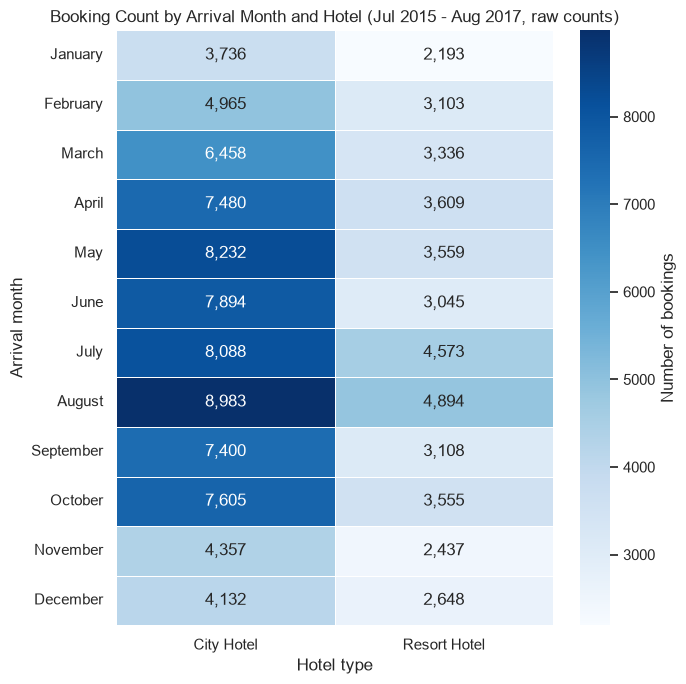

Takeaway: raw counts peak in August (13,877 bookings), but July and August are the only months covered by 3 years of data.


In [30]:
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(
    booking_pivot[['City Hotel', 'Resort Hotel']],
    annot=True, fmt=',d', cmap='Blues', linewidths=0.5,
    cbar_kws={'label': 'Number of bookings'}, ax=ax,
)

ax.set_title('Booking Count by Arrival Month and Hotel (Jul 2015 - Aug 2017, raw counts)')
ax.set_xlabel('Hotel type')
ax.set_ylabel('Arrival month')
plt.tight_layout()
plt.show()

peak = booking_pivot['Total'].idxmax()
print(f"Takeaway: raw counts peak in {peak} ({booking_pivot.loc[peak, 'Total']:,.0f} bookings), "
      f"but July and August are the only months covered by 3 years of data.")

**What we see:** raw counts reproduce the reference note - peak **August (13,877)**, lowest **January (5,929)**. But August is one of two months with 3 years of data. Per observed year the busiest month is **May (5,896)**, and August drops to rank 7 (about 4,626). The per-year view is itself pulled down for July and August by the low-volume 2015 launch period, so **2016** is the cleaner reference: busiest **October (6,203)**, August only rank 6 (5,063).

In [31]:
avg_year_pivot = booking_pivot[['City Hotel', 'Resort Hotel']].div(months_observed, axis=0)
avg_year_pivot['Total'] = avg_year_pivot.sum(axis=1)


In [32]:

full_year_pivot = (
    df[df['arrival_date_year'] == 2016]
    .pivot_table(index='arrival_date_month', columns='hotel', values='is_canceled', aggfunc='count')
    .reindex(MONTHS)
)

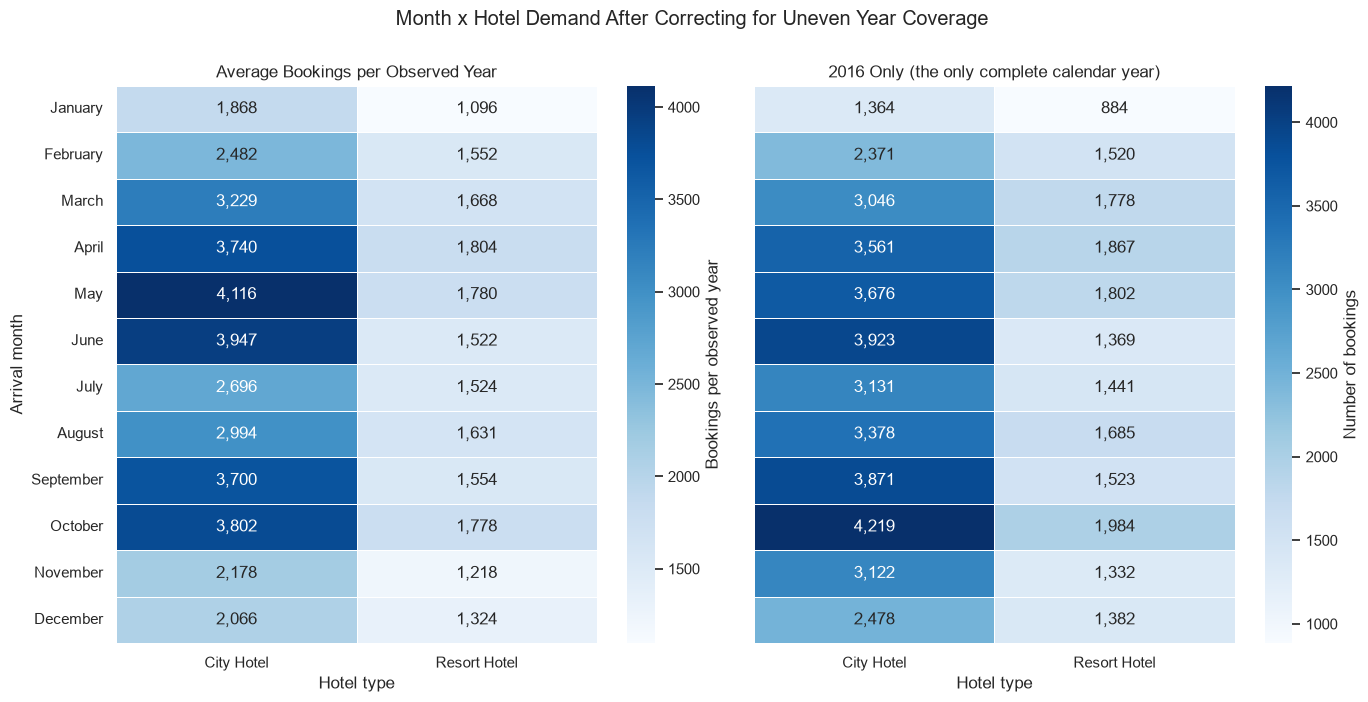

In [33]:
full_year_pivot['Total'] = full_year_pivot.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
sns.heatmap(avg_year_pivot[['City Hotel', 'Resort Hotel']], annot=True, fmt=',.0f', cmap='Blues',
            linewidths=0.5, cbar_kws={'label': 'Bookings per observed year'}, ax=axes[0])
axes[0].set_title('Average Bookings per Observed Year')
axes[0].set_xlabel('Hotel type')
axes[0].set_ylabel('Arrival month')

sns.heatmap(full_year_pivot[['City Hotel', 'Resort Hotel']], annot=True, fmt=',d', cmap='Blues',
            linewidths=0.5, cbar_kws={'label': 'Number of bookings'}, ax=axes[1])
axes[1].set_title('2016 Only (the only complete calendar year)')
axes[1].set_xlabel('Hotel type')
axes[1].set_ylabel('')
plt.suptitle('Month x Hotel Demand After Correcting for Uneven Year Coverage', y=1.0)
plt.tight_layout()
plt.show()

In [34]:
print(f"Takeaway: per observed year the busiest month is {avg_year_pivot['Total'].idxmax()} "
      f"({avg_year_pivot['Total'].max():,.0f}); in 2016 it is {full_year_pivot['Total'].idxmax()} "
      f"({full_year_pivot['Total'].max():,}). August ranks "
      f"#{int(avg_year_pivot['Total'].rank(ascending=False)['August'])} per observed year and "
      f"#{int(full_year_pivot['Total'].rank(ascending=False)['August'])} in 2016.")

Takeaway: per observed year the busiest month is May (5,896); in 2016 it is October (6,203). August ranks #7 per observed year and #6 in 2016.


> `City Hotel` receives more bookings than `Resort Hotel` in **all 12 months**; the statement that Resort "overtakes" City in summer is not supported by booking counts.

- Resort's **share** of bookings is 35.3-36.1% in July-August, but it is also **39.1% in December** and only **27.8% in June**, so this is a share pattern, not a summer takeover.
- In 2016, `City Hotel` demand peaks in **October (4,219)** and stays high in April-June and September (3,561-3,923); the lowest month is January (1,364). `Resort Hotel` peaks in October (1,984) and dips in June-July (1,369-1,441 vs 1,778-1,867 in March-May).
- Caveat: these are bookings by arrival month, not occupancy. The data has no room capacity.

### 2.3 Monthly cancellation rate per hotel

In [35]:
cancel_pivot = (
    df.pivot_table(index='arrival_date_month', columns='hotel', values='is_canceled', aggfunc='mean')
    .reindex(MONTHS) * 100
)
min_cell = (
    df.pivot_table(index='arrival_date_month', columns='hotel', values='is_canceled', aggfunc='count')
    .min().min()
)

In [36]:
hotel_avg_rate = df.groupby('hotel')['is_canceled'].mean() * 100

display(cancel_pivot)
print(f'Smallest month x hotel cell : {min_cell:,} bookings')
for hotel_name in cancel_pivot.columns:
    series = cancel_pivot[hotel_name]
    print(f'{hotel_name:<13}: high {series.idxmax()} {series.max():.1f}% | low {series.idxmin()} {series.min():.1f}% '
          f'| spread {series.max() - series.min():.1f} pp | yearly avg {hotel_avg_rate[hotel_name]:.1f}%')

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,39.67,14.82
February,38.29,25.62
March,36.95,22.87
April,46.32,29.34
May,44.38,28.77
June,44.69,33.07
July,40.88,31.40
August,40.10,33.45
September,42.03,32.37


Smallest month x hotel cell : 2,193 bookings
City Hotel   : high April 46.3% | low March 36.9% | spread 9.4 pp | yearly avg 41.7%
Resort Hotel : high August 33.4% | low January 14.8% | spread 18.6 pp | yearly avg 27.8%


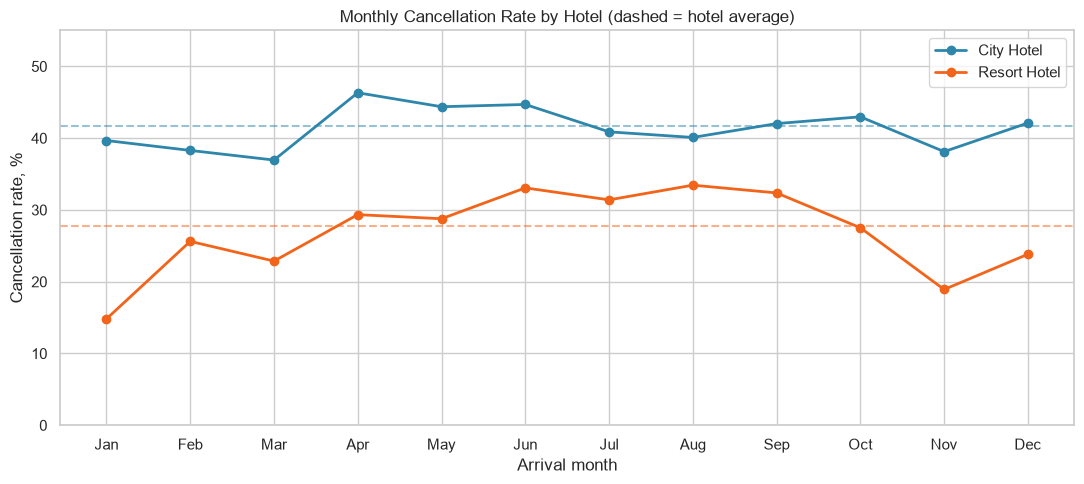

Takeaway: City Hotel cancels more than Resort Hotel in 12 of 12 months; the gap ranges from 6.6 pp (August) to 24.8 pp (January).


In [37]:
fig, ax = plt.subplots(figsize=(11, 5))
for hotel_name in cancel_pivot.columns:
    ax.plot(MONTH_SHORT, cancel_pivot[hotel_name], marker='o', linewidth=2,
            color=HOTEL_COLORS[hotel_name], label=hotel_name)
    ax.axhline(hotel_avg_rate[hotel_name], linestyle='--', alpha=0.5, color=HOTEL_COLORS[hotel_name])
ax.set_title('Monthly Cancellation Rate by Hotel (dashed = hotel average)')
ax.set_xlabel('Arrival month')
ax.set_ylabel('Cancellation rate, %')
ax.set_ylim(0, 55)
ax.legend()
plt.tight_layout()
plt.show()

gap = (cancel_pivot['City Hotel'] - cancel_pivot['Resort Hotel'])
print(f"Takeaway: City Hotel cancels more than Resort Hotel in {(gap > 0).sum()} of 12 months; "
      f"the gap ranges from {gap.min():.1f} pp ({gap.idxmin()}) to {gap.max():.1f} pp ({gap.idxmax()}).")

In [38]:
yearly_cancel = (
    df.pivot_table(index='arrival_date_year', columns='hotel', values='is_canceled', aggfunc='mean') * 100
)
display(yearly_cancel)

hotel,City Hotel,Resort Hotel
arrival_date_year,,
2015,43.88,25.72
2016,40.40,26.55
2017,42.50,30.76


In [39]:
for hotel_name in ['City Hotel', 'Resort Hotel']:
    rho, p_value = st.spearmanr(avg_year_pivot[hotel_name], cancel_pivot[hotel_name])
    print(f'{hotel_name:<13}: Spearman rho (monthly demand vs cancellation rate, n=12) = {rho:.2f}, p = {p_value:.3f}')

City Hotel   : Spearman rho (monthly demand vs cancellation rate, n=12) = 0.65, p = 0.022
Resort Hotel : Spearman rho (monthly demand vs cancellation rate, n=12) = 0.38, p = 0.217


> The `City Hotel` cancels more than `Resort Hotel` in **every month** (gap 6.6 pp in August to 24.8 pp in January).

- `City Hotel`: **36.9%** (March) to **46.3%** (April), a spread of 9.4 pp - high all year.
- `Resort Hotel`: **14.8%** (January) to **33.4%** (August), a spread of 18.6 pp - strongly seasonal; June-September sit at 31.4-33.4%, November-January at 14.8-23.8%.
- Months with more demand tend to have more cancellations for `City Hotel` (Spearman rho = 0.65, p = 0.022, n = 12 months); for `Resort Hotel` the link is weak (rho = 0.38, p = 0.217). With 12 data points this is a hint, and it shows association, not cause.
- Year-on-year `Resort Hotel` rose from 26.6% (2016) to 30.8% (2017), but 2015 and 2017 cover different months, so the trend is not like-for-like.

### 2.4 Lead time: cancelled vs not cancelled

In [40]:
lead_by_status = (
    df.groupby(['hotel', 'is_canceled'])['lead_time']
    .agg(bookings='size', mean='mean', median='median')
    .reset_index()
    .replace({'is_canceled': {0: 'Kept', 1: 'Cancelled'}})
)
overall_lead = (
    df.groupby('is_canceled')['lead_time'].agg(bookings='size', mean='mean', median='median')
    .rename(index={0: 'Kept', 1: 'Cancelled'})
)
display(lead_by_status)
display(overall_lead)
print(f"lead_time skewness : {st.skew(df['lead_time']):.2f} (mean {df['lead_time'].mean():.1f} vs median {df['lead_time'].median():.1f})")

,hotel,is_canceled,bookings,mean,median
0,City Hotel,Kept,46228,80.70,50.00
1,City Hotel,Cancelled,33102,150.28,115.00
2,Resort Hotel,Kept,28938,78.84,38.00
3,Resort Hotel,Cancelled,11122,128.68,109.00


,bookings,mean,median
is_canceled,,,
Kept,75166,79.98,45.00
Cancelled,44224,144.85,113.00


lead_time skewness : 1.35 (mean 104.0 vs median 69.0)


,bookings,cancel_rate_%,cancel_rate_excl_non_refund_%
lead_time_bin,,,
0-7,19746,9.63,9.17
8-30,18960,27.86,26.03
31-90,29553,37.70,32.20
91-180,26439,44.71,34.80
181-365,21544,55.45,39.81
365+,3148,67.66,20.65


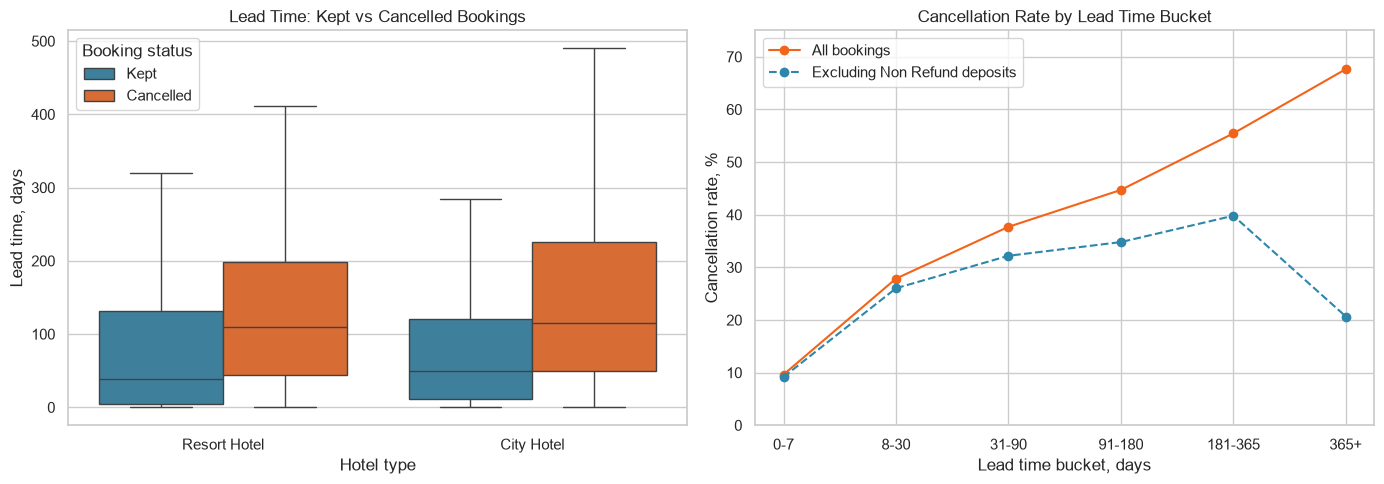

Takeaway: cancelled bookings have a median lead time of 113 days vs 45 for kept ones; the cancellation rate rises from 9.6% (0-7 days) to 67.7% (365+ days).


In [41]:
rate_by_bin = df.groupby('lead_time_bin', observed=True).agg(
    bookings=('is_canceled', 'size'),
    cancel_rate=('is_canceled', 'mean'),
)
no_refund_mask = df['deposit_type'] != 'Non Refund'
rate_by_bin['cancel_rate_excl_non_refund'] = (
    df[no_refund_mask].groupby('lead_time_bin', observed=True)['is_canceled'].mean()
)
rate_by_bin[['cancel_rate', 'cancel_rate_excl_non_refund']] *= 100
rate_by_bin = rate_by_bin.rename(columns={'cancel_rate': 'cancel_rate_%', 'cancel_rate_excl_non_refund': 'cancel_rate_excl_non_refund_%'})
display(rate_by_bin)

plot_data = df.assign(status=df['is_canceled'].map({0: 'Kept', 1: 'Cancelled'}))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=plot_data, x='hotel', y='lead_time', hue='status', hue_order=['Kept', 'Cancelled'],
            palette={'Kept': '#2E86AB', 'Cancelled': '#F26419'}, showfliers=False, ax=axes[0])
axes[0].set_title('Lead Time: Kept vs Cancelled Bookings')
axes[0].set_xlabel('Hotel type')
axes[0].set_ylabel('Lead time, days')
axes[0].legend(title='Booking status')

axes[1].plot(rate_by_bin.index.astype(str), rate_by_bin['cancel_rate_%'], marker='o', color='#F26419', label='All bookings')
axes[1].plot(rate_by_bin.index.astype(str), rate_by_bin['cancel_rate_excl_non_refund_%'], marker='o',
             color='#2E86AB', linestyle='--', label='Excluding Non Refund deposits')
axes[1].set_title('Cancellation Rate by Lead Time Bucket')
axes[1].set_xlabel('Lead time bucket, days')
axes[1].set_ylabel('Cancellation rate, %')
axes[1].set_ylim(0, 75)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Takeaway: cancelled bookings have a median lead time of {overall_lead.loc['Cancelled', 'median']:.0f} days "
      f"vs {overall_lead.loc['Kept', 'median']:.0f} for kept ones; the cancellation rate rises from "
      f"{rate_by_bin['cancel_rate_%'].iloc[0]:.1f}% (0-7 days) to {rate_by_bin['cancel_rate_%'].iloc[-1]:.1f}% (365+ days).")

> Cancelled bookings have a median lead time of **113 days vs 45** for kept bookings (mean 144.8 vs 80.0). `City Hotel`: 115 vs 50; `Resort Hotel`: 109 vs 38.

- Lead time is right-skewed (skewness 1.35, mean 104.0 vs median 69), so medians are the fairer comparison.
- The cancellation rate rises step by step: **9.6%** (0-7 days) -> 27.9% -> 37.7% -> 44.7% -> 55.5% (181-365 days) -> **67.7%** (365+ days). The claim that long lead times cancel more is confirmed.
- **Caution on the tail:** excluding `Non Refund` deposits, the curve is flatter (9.2% -> 39.8% at 181-365 days) and the 365+ bucket falls to **20.7%**. The 67.7% spike is produced by non-refundable group bookings, not by lead time itself.

### 2.5 Top 10 countries by bookings

In [42]:
country_summary = df.groupby('country').agg(
    bookings=('is_canceled', 'size'),
    cancelled=('is_canceled', 'sum'),
).reset_index()
country_summary['share_%'] = country_summary['bookings'] / len(df) * 100
country_summary['cancel_rate_%'] = country_summary['cancelled'] / country_summary['bookings'] * 100
top_countries = country_summary.sort_values('bookings', ascending=False).head(10).reset_index(drop=True)
top_countries['cumulative_share_%'] = top_countries['share_%'].cumsum()


In [43]:

display(top_countries)
print(f"Smallest country in Top 10 : {top_countries['bookings'].min():,} bookings")

,country,bookings,cancelled,share_%,cancel_rate_%,cumulative_share_%
0,PRT,48590,27519,40.70,56.64,40.70
1,GBR,12129,2453,10.16,20.22,50.86
2,FRA,10415,1934,8.72,18.57,59.58
3,ESP,8568,2177,7.18,25.41,66.76
4,DEU,7287,1218,6.10,16.71,72.86
5,ITA,3766,1333,3.15,35.40,76.02
6,IRL,3375,832,2.83,24.65,78.84
7,BEL,2342,474,1.96,20.24,80.80
8,BRA,2224,830,1.86,37.32,82.67
9,NLD,2104,387,1.76,18.39,84.43


Smallest country in Top 10 : 2,104 bookings


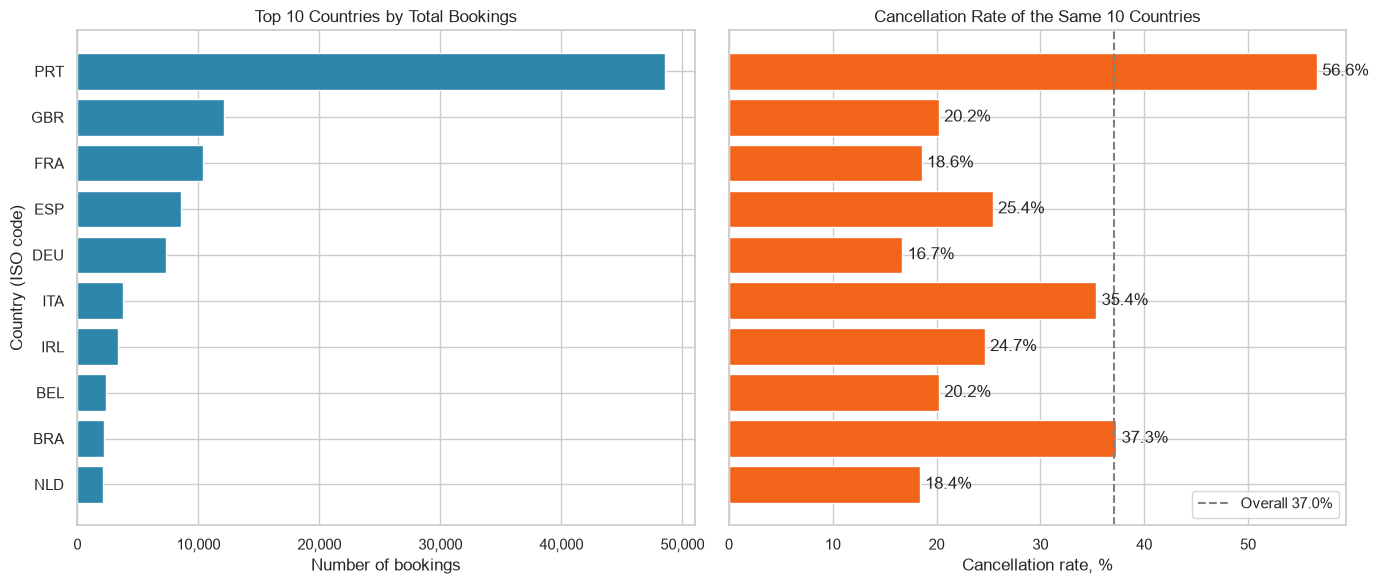

In [44]:
plot_countries = top_countries.sort_values('bookings')
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(plot_countries['country'], plot_countries['bookings'], color='#2E86AB')
axes[0].set_title('Top 10 Countries by Total Bookings')
axes[0].set_xlabel('Number of bookings')
axes[0].set_ylabel('Country (ISO code)')
axes[0].xaxis.set_major_formatter(lambda value, _: f'{value:,.0f}')

axes[1].barh(plot_countries['country'], plot_countries['cancel_rate_%'], color='#F26419')
axes[1].axvline(overall_cancel_rate, linestyle='--', color='grey', label=f'Overall {overall_cancel_rate:.1f}%')
axes[1].set_title('Cancellation Rate of the Same 10 Countries')
axes[1].set_xlabel('Cancellation rate, %')
axes[1].legend(loc='lower right')
for index, value in enumerate(plot_countries['cancel_rate_%']):
    axes[1].text(value + 0.5, index, f'{value:.1f}%', va='center')
plt.tight_layout()
plt.show()


In [45]:

top_row = top_countries.iloc[0]
print(f"Takeaway: {top_row['country']} alone is {top_row['share_%']:.1f}% of all bookings with a {top_row['cancel_rate_%']:.1f}% "
      f"cancellation rate; the Top 10 cover {top_countries['cumulative_share_%'].iloc[-1]:.1f}% of bookings.")

Takeaway: PRT alone is 40.7% of all bookings with a 56.6% cancellation rate; the Top 10 cover 84.4% of bookings.


In [46]:
prt_mask = df['country'] == 'PRT'
prt_deposit = (
    pd.concat({
        'PRT': df[prt_mask].groupby('deposit_type')['is_canceled'].agg(bookings='size', cancel_rate='mean'),
        'Other countries': df[~prt_mask].groupby('deposit_type')['is_canceled'].agg(bookings='size', cancel_rate='mean'),
    }, names=['group'])
    .reset_index()
)
prt_deposit['cancel_rate'] *= 100
display(prt_deposit.rename(columns={'cancel_rate': 'cancel_rate_%'}))


,group,deposit_type,bookings,cancel_rate_%
0,PRT,No Deposit,34366,38.86
1,PRT,Non Refund,14176,99.75
2,PRT,Refundable,48,47.92
3,Other countries,No Deposit,70275,23.25
4,Other countries,Non Refund,411,86.13
5,Other countries,Refundable,114,11.40


In [47]:

non_refund = df[df['deposit_type'] == 'Non Refund']
print(f"Non Refund bookings           : {len(non_refund):,} ({len(non_refund) / len(df) * 100:.1f}% of all)")
print(f"  ... share from PRT          : {(non_refund['country'] == 'PRT').mean() * 100:.1f}%")
print(f"  ... share at City Hotel     : {(non_refund['hotel'] == 'City Hotel').mean() * 100:.1f}%")
print(f"  ... cancellation rate       : {non_refund['is_canceled'].mean() * 100:.1f}%")
print(f"  ... share of ALL cancellations: {non_refund['is_canceled'].sum() / df['is_canceled'].sum() * 100:.1f}%")
print(f"PRT cancellation rate excl. Non Refund : {df[prt_mask & no_refund_mask]['is_canceled'].mean() * 100:.1f}%")
print(f"Other countries rate excl. Non Refund  : {df[~prt_mask & no_refund_mask]['is_canceled'].mean() * 100:.1f}%")

Non Refund bookings           : 14,587 (12.2% of all)
  ... share from PRT          : 97.2%
  ... share at City Hotel     : 88.2%
  ... cancellation rate       : 99.4%
  ... share of ALL cancellations: 32.8%
PRT cancellation rate excl. Non Refund : 38.9%
Other countries rate excl. Non Refund  : 23.2%


> `PRT` (Portugal) has **48,590 bookings (40.7%)** with a **56.6%** cancellation rate; the Top 10 countries cover **84.4%** of bookings.

- The reference note lists 28.2k bookings for `PRT`; the data shows **48,590**.
- Other Top 10 rates: ITA 35.4% and BRA 37.3% are close to the 37.0% overall rate; GBR 20.2%, FRA 18.6%, DEU 16.7%, NLD 18.4%, BEL 20.2% are well below it; ESP 25.4%, IRL 24.7%.
- **`PRT` is a deposit story.** `Non Refund` bookings are 14,587 rows (12.2% of the data): **97.2% from `PRT`**, **88.2% at `City Hotel`**, **99.4% cancelled** - about a third of all cancellations. `PRT` with `No Deposit` cancels at 38.9%, still above 23.2% for other countries, so the country gap is real but much smaller than 56.6% vs 23.6% for the rest suggests.

### 2.6 Demand by market segment

In [48]:
segment_summary = df.groupby('market_segment').agg(
    bookings=('is_canceled', 'size'),
    cancelled=('is_canceled', 'sum'),
    avg_lead_time=('lead_time', 'mean'),
    median_lead_time=('lead_time', 'median'),
).reset_index()


In [49]:
segment_summary['share_%'] = segment_summary['bookings'] / len(df) * 100
segment_summary['cancel_rate_%'] = segment_summary['cancelled'] / segment_summary['bookings'] * 100
segment_summary['cancel_share_%'] = segment_summary['cancelled'] / segment_summary['cancelled'].sum() * 100
segment_adr = (
    df[df['adr_valid'] & (df['is_canceled'] == 0)]
    .groupby('market_segment')['adr'].mean().rename('avg_adr_kept').reset_index()
)


In [50]:
segment_summary = (
    segment_summary.merge(segment_adr, on='market_segment', how='left')
    .sort_values('bookings', ascending=False).reset_index(drop=True)
)
display(segment_summary)


,market_segment,bookings,cancelled,avg_lead_time,median_lead_time,share_%,cancel_rate_%,cancel_share_%,avg_adr_kept
0,Online TA,56477,20739,83.00,58.00,47.30,36.72,46.90,114.98
1,Offline TA/TO,24219,8311,135.00,109.00,20.29,34.32,18.79,84.98
2,Groups,19811,12097,186.97,162.00,16.59,61.06,27.35,79.48
3,Direct,12606,1934,49.86,16.00,10.56,15.34,4.37,116.15
4,Corporate,5295,992,22.13,7.00,4.44,18.73,2.24,68.33
5,Complementary,743,97,13.29,3.00,0.62,13.06,0.22,34.29
6,Aviation,237,52,4.44,3.00,0.20,21.94,0.12,102.25
7,Undefined,2,2,1.50,1.50,0.00,100.00,0.00,NaN


In [51]:

transient_share = (df['customer_type'] == 'Transient').mean() * 100
print(f"Customer type 'Transient' share of bookings : {transient_share:.1f}%")

Customer type 'Transient' share of bookings : 75.1%


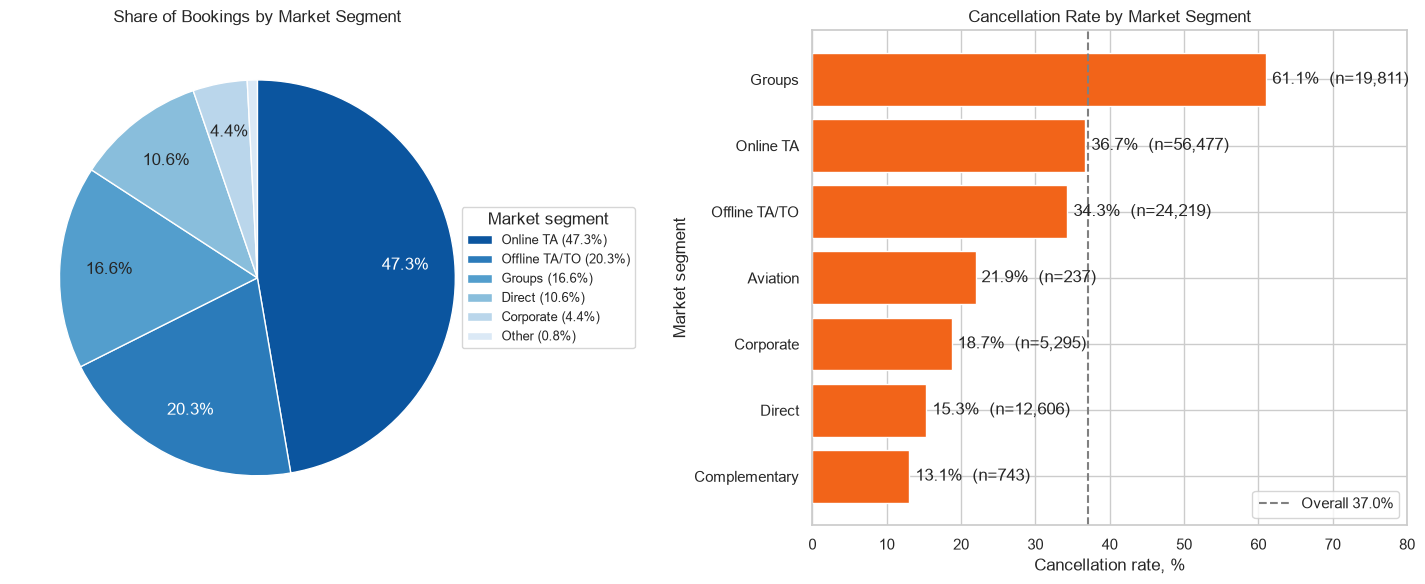

In [52]:
pie_data = segment_summary.set_index('market_segment')['bookings'].copy()
small_segments = ['Complementary', 'Aviation', 'Undefined']
pie_data['Other'] = pie_data.loc[small_segments].sum()
pie_data = pie_data.drop(small_segments).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
wedges, _, autotexts = axes[0].pie(
    pie_data, autopct=lambda pct: f'{pct:.1f}%' if pct >= 3 else '', startangle=90, counterclock=False,
    colors=sns.color_palette('Blues_r', len(pie_data)), wedgeprops={'edgecolor': 'white'}, pctdistance=0.75,
)
for autotext in autotexts[:2]:
    autotext.set_color('white')
axes[0].legend(wedges, [f'{name} ({share:.1f}%)' for name, share in zip(pie_data.index, pie_data / pie_data.sum() * 100)],
               title='Market segment', loc='center left', bbox_to_anchor=(0.9, 0.5), fontsize=9)
axes[0].set_title('Share of Bookings by Market Segment')

rate_plot = segment_summary[segment_summary['market_segment'] != 'Undefined'].sort_values('cancel_rate_%')
bars = axes[1].barh(rate_plot['market_segment'], rate_plot['cancel_rate_%'], color='#F26419')
axes[1].axvline(overall_cancel_rate, linestyle='--', color='grey', label=f'Overall {overall_cancel_rate:.1f}%')
axes[1].set_title('Cancellation Rate by Market Segment')
axes[1].set_xlabel('Cancellation rate, %')
axes[1].set_ylabel('Market segment')
for bar, (_, row) in zip(bars, rate_plot.iterrows()):
    axes[1].text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
                 f"{row['cancel_rate_%']:.1f}%  (n={row['bookings']:,.0f})", va='center')
axes[1].set_xlim(0, 80)
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()


In [53]:

eligible = segment_summary[(segment_summary['bookings'] >= 1000)]
lowest = eligible.loc[eligible['cancel_rate_%'].idxmin()]
highest = eligible.loc[eligible['cancel_rate_%'].idxmax()]
print(f"Takeaway: lowest cancellation among segments with >= 1,000 bookings is {lowest['market_segment']} "
      f"({lowest['cancel_rate_%']:.1f}%); highest is {highest['market_segment']} ({highest['cancel_rate_%']:.1f}%).")

Takeaway: lowest cancellation among segments with >= 1,000 bookings is Direct (15.3%); highest is Groups (61.1%).


In [54]:
segment_deposit = (
    df[df['market_segment'] != 'Undefined']
    .groupby(['market_segment', 'deposit_type'])['is_canceled']
    .agg(bookings='size', cancel_rate='mean')
    .reset_index()
    .query('bookings >= 100')
)


In [55]:
segment_deposit['cancel_rate'] *= 100
display(segment_deposit.rename(columns={'cancel_rate': 'cancel_rate_%'}))


,market_segment,deposit_type,bookings,cancel_rate_%
0,Aviation,No Deposit,237,21.94
1,Complementary,No Deposit,743,13.06
2,Corporate,No Deposit,4957,13.70
3,Corporate,Non Refund,334,93.41
5,Direct,No Deposit,12581,15.23
8,Groups,No Deposit,10509,28.30
9,Groups,Non Refund,9172,99.32
10,Groups,Refundable,130,10.00
11,Offline TA/TO,No Deposit,19209,17.21
12,Offline TA/TO,Non Refund,5006,99.94


In [56]:

segment_excl = (
    df[no_refund_mask & (df['market_segment'] != 'Undefined')]
    .groupby('market_segment')['is_canceled'].agg(bookings='size', cancel_rate='mean')
    .sort_values('cancel_rate')
)


In [57]:
segment_excl['cancel_rate'] *= 100
print('Cancellation rate by segment excluding Non Refund deposits:')
display(segment_excl.rename(columns={'cancel_rate': 'cancel_rate_%'}))

Cancellation rate by segment excluding Non Refund deposits:


,bookings,cancel_rate_%
market_segment,,
Complementary,743,13.06
Corporate,4961,13.71
Direct,12587,15.24
Offline TA/TO,19213,17.22
Aviation,237,21.94
Groups,10639,28.08
Online TA,56421,36.66


> `Online TA` is 47.3% of bookings and 46.9% of all cancellations; `Groups` cancel at the highest rate (**61.1%**); `Direct` has the lowest rate among segments with at least 1,000 bookings (**15.3%**).

- `Complementary` is lower (13.1%) but has only 743 bookings and an average ADR of about 34 (free stays), so it is not a comparable commercial segment.
- Excluding `Non Refund` deposits: `Groups` falls from 61.1% to **28.1%**, `Offline TA/TO` from 34.3% to 17.2%, `Corporate` from 18.7% to 13.7% - while `Online TA` stays at **36.7%**. On flexible bookings `Online TA` is the highest-risk segment.
- `Direct` and `Online TA` earn almost the same ADR on kept bookings (116.2 vs 115.0), but `Direct` cancels 2.4x less often.
- `Transient` customers are **75.1%** of bookings, matching the reference note.

### 2.7 Bonus: average daily rate (ADR) by month and hotel

In [58]:
adr_kept = df[df['adr_valid'] & (df['is_canceled'] == 0)]
adr_pivot = (
    adr_kept.pivot_table(index='arrival_date_month', columns='hotel', values='adr', aggfunc='mean')
    .reindex(MONTHS)
)


In [59]:
adr_median_pivot = (
    adr_kept.pivot_table(index='arrival_date_month', columns='hotel', values='adr', aggfunc='median')
    .reindex(MONTHS)
)

In [60]:
kept_stays_2016 = (
    df[(df['is_canceled'] == 0) & (df['arrival_date_year'] == 2016)]
    .groupby('arrival_date_month').size().reindex(MONTHS)
)
display(adr_pivot)

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,84.37,50.24
February,88.35,55.40
March,92.05,58.33
April,113.53,77.60
May,123.16,78.55
June,119.65,109.92
July,117.93,152.80
August,120.91,183.69
September,115.51,97.58


In [61]:

print(f"ADR rows used : {len(adr_kept):,} kept bookings with 0 < adr < 1,000 "
      f"(excluded {((df['is_canceled'] == 0) & ~df['adr_valid']).sum():,} kept bookings)")
for hotel_name in adr_pivot.columns:
    series = adr_pivot[hotel_name]
    print(f'{hotel_name:<13}: low {series.idxmin()} {series.min():.1f} | high {series.idxmax()} {series.max():.1f} '
          f'| high/low = {series.max() / series.min():.2f}x')

ADR rows used : 73,419 kept bookings with 0 < adr < 1,000 (excluded 1,747 kept bookings)
City Hotel   : low January 84.4 | high May 123.2 | high/low = 1.46x
Resort Hotel : low November 50.2 | high August 183.7 | high/low = 3.66x


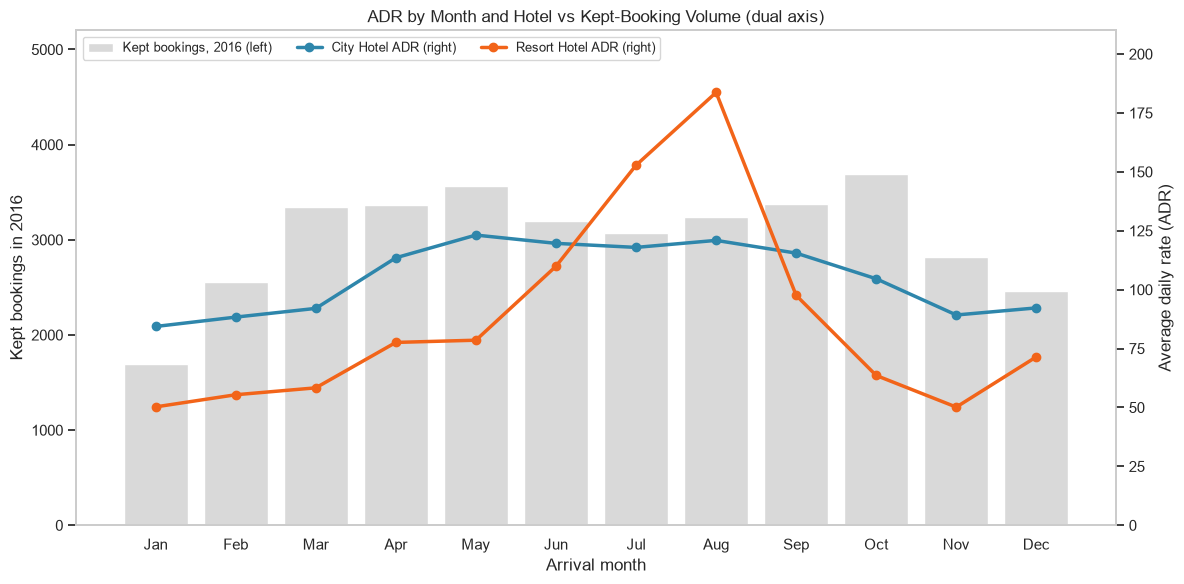

Takeaway: Resort ADR swings from 50 (November) to 184 (August), while City ADR stays between 84 and 123.


In [62]:
fig, ax_volume = plt.subplots(figsize=(12, 6))
ax_volume.bar(MONTH_SHORT, kept_stays_2016, color='#D9D9D9', label='Kept bookings, 2016 (left)')
ax_volume.set_xlabel('Arrival month')
ax_volume.set_ylabel('Kept bookings in 2016')
ax_volume.set_ylim(0, 5200)
ax_volume.grid(False)

ax_adr = ax_volume.twinx()
for hotel_name in adr_pivot.columns:
    ax_adr.plot(MONTH_SHORT, adr_pivot[hotel_name], marker='o', linewidth=2.5,
                color=HOTEL_COLORS[hotel_name], label=f'{hotel_name} ADR (right)')
ax_adr.set_ylabel('Average daily rate (ADR)')
ax_adr.set_ylim(0, 210)
ax_adr.grid(False)
ax_volume.set_title('ADR by Month and Hotel vs Kept-Booking Volume (dual axis)')

handles = ax_volume.get_legend_handles_labels()[0] + ax_adr.get_legend_handles_labels()[0]
labels = ax_volume.get_legend_handles_labels()[1] + ax_adr.get_legend_handles_labels()[1]
ax_volume.legend(handles, labels, loc='upper left', ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

resort = adr_pivot['Resort Hotel']
city = adr_pivot['City Hotel']
print(f"Takeaway: Resort ADR swings from {resort.min():.0f} ({resort.idxmin()}) to {resort.max():.0f} ({resort.idxmax()}), "
      f"while City ADR stays between {city.min():.0f} and {city.max():.0f}.")

> `Resort Hotel` ADR swings **3.7x** (50 in November to 184 in August); `City Hotel` ADR only **1.5x** (84 in January to 123 in May).

- The Resort summer premium appears in July (153) and August (184); in June Resort ADR (110) is still below `City Hotel` (120).
- So Resort wins in summer on **price**, not on booking volume (2016 Resort bookings in June-July, 1,369-1,441, are below its March-May and October levels of 1,778-1,984).
- ADR is a plain average over room types and meal plans; mix is not controlled.

### 2.8 Revenue exposure from cancellations

In [63]:
revenue_df = df[df['adr_valid']]
revenue_summary = (
    revenue_df.pivot_table(index='hotel', columns='is_canceled', values='room_revenue', aggfunc='sum')
    .rename(columns={0: 'kept_revenue', 1: 'cancelled_revenue'})
)

In [64]:
revenue_summary['cancelled_share_%'] = (
    revenue_summary['cancelled_revenue'] / revenue_summary.sum(axis=1) * 100
)

In [65]:
non_refundable_cancelled = (
    revenue_df[(revenue_df['is_canceled'] == 1) & (revenue_df['deposit_type'] == 'Non Refund')]
    .groupby('hotel')['room_revenue'].sum()
)

In [66]:
revenue_summary['cancelled_non_refund'] = non_refundable_cancelled
revenue_summary['cancelled_flexible'] = revenue_summary['cancelled_revenue'] - revenue_summary['cancelled_non_refund']
display(revenue_summary)

is_canceled,kept_revenue,cancelled_revenue,cancelled_share_%,cancelled_non_refund,cancelled_flexible
hotel,,,,,
City Hotel,"14,394,410.18","10,879,659.78",43.05,"3,160,872.84","7,718,786.94"
Resort Hotel,"11,601,914.03","5,842,177.34",33.49,"438,064.19","5,404,113.15"


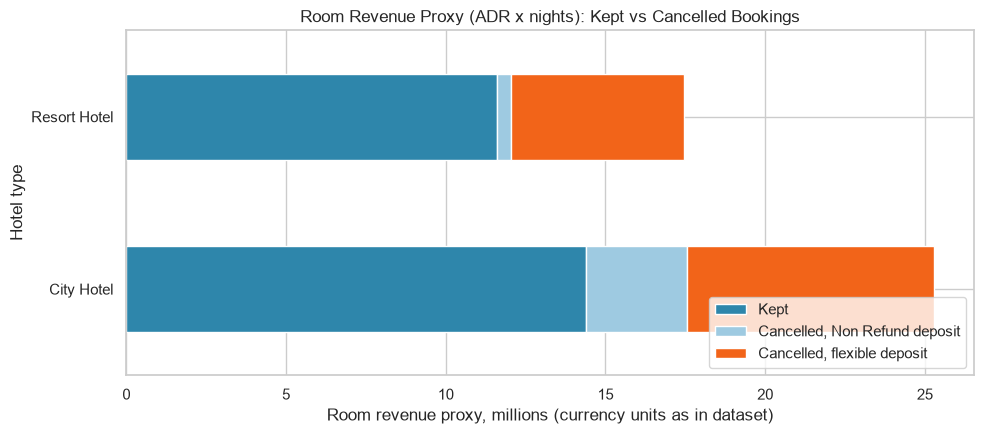

City Hotel   : 43.0% of potential room revenue sits in cancelled bookings; flexible-deposit cancellations alone = 30.5%
Resort Hotel : 33.5% of potential room revenue sits in cancelled bookings; flexible-deposit cancellations alone = 31.0%


In [67]:

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_revenue = revenue_summary[['kept_revenue', 'cancelled_non_refund', 'cancelled_flexible']] / 1e6
plot_revenue.plot(kind='barh', stacked=True, ax=ax, color=['#2E86AB', '#9ECAE1', '#F26419'])
ax.set_title('Room Revenue Proxy (ADR x nights): Kept vs Cancelled Bookings')
ax.set_xlabel('Room revenue proxy, millions (currency units as in dataset)')
ax.set_ylabel('Hotel type')
ax.legend(['Kept', 'Cancelled, Non Refund deposit', 'Cancelled, flexible deposit'], loc='lower right')
plt.tight_layout()
plt.show()

for hotel_name, row in revenue_summary.iterrows():
    print(f"{hotel_name:<13}: {row['cancelled_share_%']:.1f}% of potential room revenue sits in cancelled bookings; "
          f"flexible-deposit cancellations alone = {row['cancelled_flexible'] / (row['kept_revenue'] + row['cancelled_revenue']) * 100:.1f}%")

> **43.0%** of potential room revenue at `City Hotel` (10.9M of 25.3M) and **33.5%** at `Resort Hotel` (5.8M of 17.4M) sits in cancelled bookings (proxy: `adr` x nights).

- Of the cancelled revenue, `Non Refund` bookings are 3.2M (City) and 0.4M (Resort). If those deposits are kept by the hotel, the truly exposed revenue is the flexible-deposit part: **30.5% at City and 31.0% at Resort - almost identical**.
- So the headline gap between the hotels (41.7% vs 27.8%) is mostly a `Non Refund` effect, not a difference in guest behaviour.
- The data does not say whether deposits were collected, so the proxy gives a range, not a loss figure.

### 2.9 Cancellation drivers

In [68]:
df['special_requests_bin'] = df['total_of_special_requests'].clip(upper=3).astype(str).replace({'3': '3+'})
df['previous_cancellations_bin'] = df['previous_cancellations'].clip(upper=2).astype(str).replace({'2': '2+'})
df['booking_changes_bin'] = df['booking_changes'].clip(upper=2).astype(str).replace({'2': '2+'})
df['parking_bin'] = np.where(df['required_car_parking_spaces'] > 0, '1+ spaces', 'No parking')


In [69]:

driver_columns = [
    ('deposit_type', 'Deposit type'),
    ('customer_type', 'Customer type'),
    ('special_requests_bin', 'Special requests'),
    ('previous_cancellations_bin', 'Previous cancellations'),
    ('booking_changes_bin', 'Booking changes'),
    ('parking_bin', 'Car parking'),
]


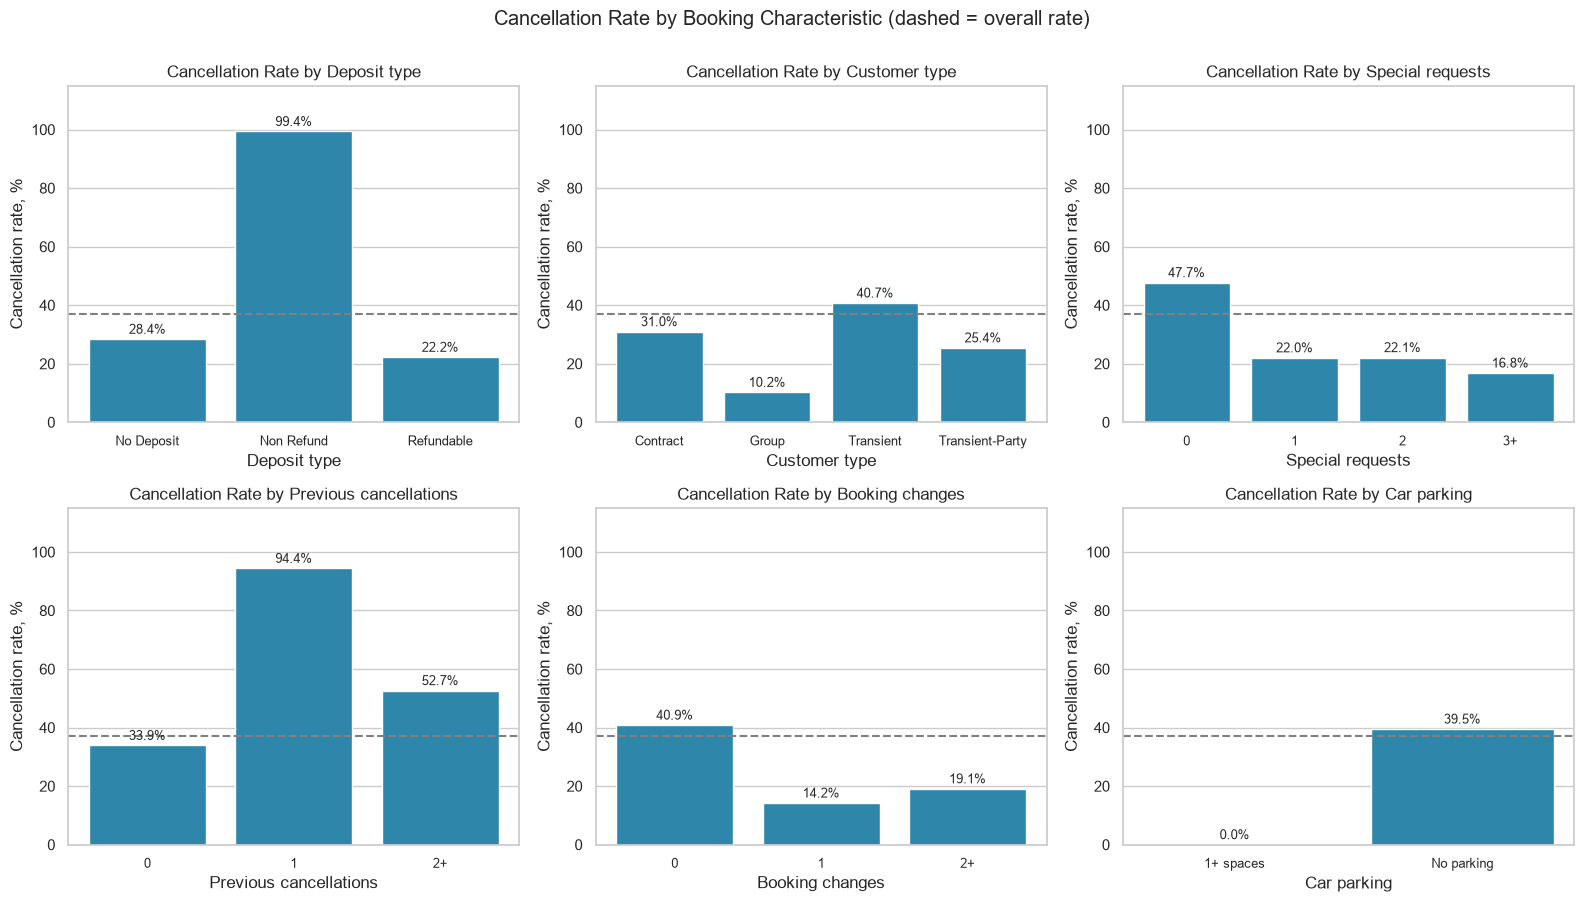

Takeaway: Non Refund deposits cancel at 99.4% vs 28.4% for No Deposit; bookings with 0 special requests cancel at 47.7%, with 1+ at 21.7%.
Overlap check: of bookings with exactly 1 previous cancellation, 58.4% are Non Refund and 95.7% are PRT.


In [70]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (column, label) in zip(axes.ravel(), driver_columns):
    summary = df.groupby(column)['is_canceled'].agg(bookings='size', rate='mean')
    summary['rate'] *= 100
    bars = ax.bar(summary.index, summary['rate'], color='#2E86AB')
    ax.bar_label(bars, labels=[f'{v:.1f}%' for v in summary['rate']], padding=2, fontsize=9)
    ax.axhline(overall_cancel_rate, linestyle='--', color='grey')
    ax.set_title(f'Cancellation Rate by {label}')
    ax.set_xlabel(label)
    ax.set_ylabel('Cancellation rate, %')
    ax.set_ylim(0, 115)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='x', visible=False)
plt.suptitle('Cancellation Rate by Booking Characteristic (dashed = overall rate)', y=1.0)
plt.tight_layout()
plt.show()

prev_one = df[df['previous_cancellations'] == 1]
print(f"Takeaway: Non Refund deposits cancel at {non_refund['is_canceled'].mean() * 100:.1f}% vs "
      f"{df[df['deposit_type'] == 'No Deposit']['is_canceled'].mean() * 100:.1f}% for No Deposit; "
      f"bookings with 0 special requests cancel at "
      f"{df[df['total_of_special_requests'] == 0]['is_canceled'].mean() * 100:.1f}%, with 1+ at "
      f"{df[df['total_of_special_requests'] > 0]['is_canceled'].mean() * 100:.1f}%.")
print(f"Overlap check: of bookings with exactly 1 previous cancellation, {(prev_one['deposit_type'] == 'Non Refund').mean() * 100:.1f}% "
      f"are Non Refund and {(prev_one['country'] == 'PRT').mean() * 100:.1f}% are PRT.")

> `Non Refund` deposit (**99.4%**) is by far the strongest single marker; guests with no special request cancel at **47.7%** vs **21.7%** with at least one; no booking changes: 40.9% vs 14.2% with one change.

- `Transient` customers cancel at 40.7%, `Group` at 10.2% (577 bookings only).
- **`previous_cancellations = 1` shows 94.4%** - but 95.7% of those bookings are `PRT` and 58.4% are `Non Refund`: the same cluster seen again, not an independent signal.
- **Caution on timing:** special requests, booking changes and parking spaces (0.0% cancellation with 1+ spaces) can be recorded after the booking and only for stays that continue, so they follow the outcome. They are indicators, not levers.

## 3. Statistical Analysis

All tests use `alpha = 0.05`. With 119,390 rows **every difference will be statistically significant**, so effect sizes (Cramer's V, rank-biserial r) decide whether a difference matters. Correlation does not equal causation: none of these tests shows that changing one variable changes cancellations.

In [71]:
lead_results = []
groups = {'All hotels': df, 'City Hotel': df[df['hotel'] == 'City Hotel'], 'Resort Hotel': df[df['hotel'] == 'Resort Hotel']}
for name, subset in groups.items():
    cancelled_lead = subset.loc[subset['is_canceled'] == 1, 'lead_time']
    kept_lead = subset.loc[subset['is_canceled'] == 0, 'lead_time']
    # Mann-Whitney because lead_time is strongly right-skewed (see skewness above)
    u_stat, p_value = st.mannwhitneyu(cancelled_lead, kept_lead, alternative='two-sided')
    cles = u_stat / (len(cancelled_lead) * len(kept_lead))
    lead_results.append({
        'group': name,
        'n_cancelled': len(cancelled_lead),
        'n_kept': len(kept_lead),
        'median_cancelled': cancelled_lead.median(),
        'median_kept': kept_lead.median(),
        'p_value': p_value,
        'P(cancelled > kept)': cles,
        'rank_biserial_r': 2 * cles - 1,
    })

In [72]:
lead_results = pd.DataFrame(lead_results)

print('H0: lead_time distributions of cancelled and kept bookings are the same')
print('H1: cancelled bookings have a different (longer) lead_time distribution')
print(f'alpha = {ALPHA}')
display(lead_results)
decision = 'Reject H0' if (lead_results['p_value'] < ALPHA).all() else 'Fail to reject H0 in at least one group'
print(f'Conclusion: {decision}: cancelled bookings are booked earlier in every group tested.')

rho, p_value = st.spearmanr(df['lead_time'], df['is_canceled'])
print(f'\nSpearman lead_time vs is_canceled: rho = {rho:.3f}, p < 0.001 -> association, not causation')

H0: lead_time distributions of cancelled and kept bookings are the same
H1: cancelled bookings have a different (longer) lead_time distribution
alpha = 0.05


,group,n_cancelled,n_kept,median_cancelled,median_kept,p_value,P(cancelled > kept),rank_biserial_r
0,All hotels,44224,75166,113.00,45.00,0.00,0.69,0.38
1,City Hotel,33102,46228,115.00,50.00,0.00,0.69,0.38
2,Resort Hotel,11122,28938,109.00,38.00,0.00,0.68,0.36


Conclusion: Reject H0: cancelled bookings are booked earlier in every group tested.

Spearman lead_time vs is_canceled: rho = 0.317, p < 0.001 -> association, not causation


In [73]:
def chi_square_test(data: pd.DataFrame, column: str, label: str) -> None:
    """Chi-square test of independence between `column` and is_canceled, with Cramer's V."""
    table = pd.crosstab(data[column], data['is_canceled'])
    chi2, p_value, dof, _ = st.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rates = (table[1] / table.sum(axis=1) * 100).round(1)
    print(f'--- {label} ---')
    print(f'H0: cancellation is independent of {column}')
    print(f'H1: cancellation depends on {column}')
    print(f'n = {table.values.sum():,} | chi2 = {chi2:,.1f} | dof = {dof} | p {"< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"} '
          f"| Cramer's V = {cramers_v:.3f}")
    print('Cancellation rate by group, %:', rates.to_dict())
    verdict = 'Reject' if p_value < ALPHA else 'Fail to reject'
    print(f'Conclusion: {verdict} H0 -> {label} is associated with cancellation (V = {cramers_v:.2f}).\n')


chi_square_test(df, 'hotel', 'Hotel type')
chi_square_test(df[df['market_segment'] != 'Undefined'], 'market_segment', 'Market segment')
chi_square_test(df, 'deposit_type', 'Deposit type')
chi_square_test(df, 'customer_type', 'Customer type')

--- Hotel type ---
H0: cancellation is independent of hotel
H1: cancellation depends on hotel
n = 119,390 | chi2 = 2,224.9 | dof = 1 | p < 0.001 | Cramer's V = 0.137
Cancellation rate by group, %: {'City Hotel': 41.7, 'Resort Hotel': 27.8}
Conclusion: Reject H0 -> Hotel type is associated with cancellation (V = 0.14).

--- Market segment ---
H0: cancellation is independent of market_segment
H1: cancellation depends on market_segment
n = 119,388 | chi2 = 8,493.9 | dof = 6 | p < 0.001 | Cramer's V = 0.267
Cancellation rate by group, %: {'Aviation': 21.9, 'Complementary': 13.1, 'Corporate': 18.7, 'Direct': 15.3, 'Groups': 61.1, 'Offline TA/TO': 34.3, 'Online TA': 36.7}
Conclusion: Reject H0 -> Market segment is associated with cancellation (V = 0.27).

--- Deposit type ---
H0: cancellation is independent of deposit_type
H1: cancellation depends on deposit_type
n = 119,390 | chi2 = 27,677.3 | dof = 2 | p < 0.001 | Cramer's V = 0.481
Cancellation rate by group, %: {'No Deposit': 28.4, 'Non 

> **Lead time:** significant in all groups (p < 0.001). A random cancelled booking has a longer lead time than a random kept booking in **69%** of pairs (rank-biserial r = 0.38; City 0.38, Resort 0.36) - a medium effect.

> **Chi-square (effect size, Cramer's V):** `deposit_type` **0.48** (large) > `market_segment` **0.27** (medium) > `hotel` 0.14 ~ `customer_type` 0.14 (small).

Deposit type dominates, but its assignment is not random (97% of `Non Refund` are `PRT`), so it is an association, not proof that a deposit policy change would reproduce 99.4%. Spearman rho for lead time vs cancellation is 0.317: association only.

In [74]:
scenarios = {
    'Full dataset': df,
    'Without Non Refund deposits': df[no_refund_mask],
    'Without duplicate rows': df[~raw.duplicated()],
    'Without PRT': df[~prt_mask],
}
robustness = []
for name, subset in scenarios.items():
    robustness.append({
        'scenario': name,
        'rows': len(subset),
        'cancel_rate_%': subset['is_canceled'].mean() * 100,
        'city_%': subset.loc[subset['hotel'] == 'City Hotel', 'is_canceled'].mean() * 100,
        'resort_%': subset.loc[subset['hotel'] == 'Resort Hotel', 'is_canceled'].mean() * 100,
        'median_lead_cancelled': subset.loc[subset['is_canceled'] == 1, 'lead_time'].median(),
        'median_lead_kept': subset.loc[subset['is_canceled'] == 0, 'lead_time'].median(),
    })
robustness = pd.DataFrame(robustness)
robustness['city_minus_resort_pp'] = robustness['city_%'] - robustness['resort_%']
robustness

,scenario,rows,cancel_rate_%,city_%,resort_%,median_lead_cancelled,median_lead_kept,city_minus_resort_pp
0,Full dataset,119390,37.04,41.73,27.76,113.00,45.00,13.96
1,Without Non Refund deposits,104803,28.37,30.48,24.70,86.00,45.00,5.78
2,Without duplicate rows,87396,27.49,30.04,23.48,80.00,38.00,6.56
3,Without PRT,70800,23.59,26.92,16.42,89.00,61.00,10.50


**Robustness check - what survives and what does not**

- **Direction survives every check:** `City Hotel` cancels more than `Resort Hotel`, and cancelled bookings are booked earlier (median 80-113 days vs 38-61 days).
- **Magnitude does not:** the headline 37.0% falls to **28.4%** without `Non Refund` deposits and to **27.5%** without duplicate rows; the City-Resort gap shrinks from **14.0 pp to 5.8 pp** (no `Non Refund`) or 6.6 pp (no duplicates).
- Without `PRT` the overall rate is 23.6% and the gap is 10.5 pp.
- The headline cancellation rates should always be quoted together with the `Non Refund` share.

### Check against the reference notes in the task

In [75]:
prt_bookings = int((df['country'] == 'PRT').sum())
peak_raw, low_raw = booking_pivot['Total'].idxmax(), booking_pivot['Total'].idxmin()
lead_means = df.groupby('hotel')['lead_time'].mean()

In [76]:

city_gt_resort = int((booking_pivot['City Hotel'] > booking_pivot['Resort Hotel']).sum())
reference_check = pd.DataFrame([
    ('Rows x columns', '119,390 x 32', f'{raw.shape[0]:,} x {raw.shape[1]}', raw.shape == (119390, 32)),
    ('Cancellation rate, City Hotel', '41.7%', f"{hotel_avg_rate['City Hotel']:.1f}%", round(hotel_avg_rate['City Hotel'], 1) == 41.7),
    ('Cancellation rate, Resort Hotel', '27.8%', f"{hotel_avg_rate['Resort Hotel']:.1f}%", round(hotel_avg_rate['Resort Hotel'], 1) == 27.8),
    ('Highest month by raw count', 'August (13.8k)', f"{peak_raw} ({booking_pivot.loc[peak_raw, 'Total']:,.0f})",
     peak_raw == 'August' and abs(booking_pivot.loc[peak_raw, 'Total'] - 13800) < 100),
    ('Lowest month by raw count', 'January (5.9k)', f"{low_raw} ({booking_pivot.loc[low_raw, 'Total']:,.0f})",
     low_raw == 'January' and abs(booking_pivot.loc[low_raw, 'Total'] - 5900) < 100),
    ('Mean lead_time, City Hotel', '110 days', f"{lead_means['City Hotel']:.1f} days", abs(lead_means['City Hotel'] - 110) < 1),
    ('Mean lead_time, Resort Hotel', '92 days', f"{lead_means['Resort Hotel']:.1f} days", abs(lead_means['Resort Hotel'] - 92) < 1),
    ('PRT bookings', '28.2k', f'{prt_bookings:,}', abs(prt_bookings - 28200) < 500),
    ("'Transient' share of bookings", '75%', f'{transient_share:.1f}%', abs(transient_share - 75) < 1),
    ('Resort > City in summer (monthly count)', 'Yes',
     f"City higher in {city_gt_resort} of 12 months; Resort share peaks at "
     f"{booking_pivot['resort_share_%'].max():.1f}% in {booking_pivot['resort_share_%'].idxmax()}", city_gt_resort < 12),
], columns=['claim', 'reference note', 'computed here', 'matches'])
reference_check['verdict'] = reference_check['matches'].map({True: 'Confirmed', False: 'Not confirmed'})
reference_check.drop(columns='matches')

,claim,reference note,computed here,verdict
0,Rows x columns,"119,390 x 32","119,390 x 32",Confirmed
1,"Cancellation rate, City Hotel",41.7%,41.7%,Confirmed
2,"Cancellation rate, Resort Hotel",27.8%,27.8%,Confirmed
3,Highest month by raw count,August (13.8k),"August (13,877)",Confirmed
4,Lowest month by raw count,January (5.9k),"January (5,929)",Confirmed
5,"Mean lead_time, City Hotel",110 days,109.7 days,Confirmed
6,"Mean lead_time, Resort Hotel",92 days,92.7 days,Confirmed
7,PRT bookings,28.2k,"48,590",Not confirmed
8,'Transient' share of bookings,75%,75.1%,Confirmed
9,Resort > City in summer (monthly count),Yes,City higher in 12 of 12 months; Resort share p...,Not confirmed


Eight of the ten reference-note statements are reproduced (the August 13.8k vs 13.9k and lead-time 92 vs 92.7 differences are rounding). Two are **not** supported by the data:

- `PRT` bookings: the reference lists 28.2k, the data has **48,590**.
- "Resort Hotel exceeds City Hotel in summer": City has more bookings in all 12 months; only Resort's *share* and *ADR* are higher in July-August.

The note.md deliverable uses the computed values.

## 4. Final Summary

### Key Findings



1. **Overall cancellation rate is 37.0%.** City Hotel records a higher cancellation rate (41.7%) than Resort Hotel (27.8%). The dataset also contains 1,207 no-shows.

2. **Seasonality is less pronounced than raw monthly totals suggest.** August leads in aggregate booking counts partly because July and August appear three times in the observation period. Using the complete year of 2016 as the baseline, October records the highest demand (6,203 bookings), while January is consistently the weakest month.

3. **Resort Hotel exhibits stronger seasonal variation than City Hotel.** Resort ADR ranges from 50 to 184, with monthly cancellation rates between 14.8% and 33.4%. City Hotel shows a narrower ADR range of 84–123 and persistently higher cancellation rates of 36.9%–46.3%.

4. **Longer lead times are associated with higher cancellation risk.** Cancelled bookings have a median lead time of 113 days, compared with 45 days for non-cancelled bookings. Among flexible-deposit bookings, cancellation rates rise from 9.2% for lead times of 0–7 days to 39.8% for 181–365 days.

5. **Non-Refundable bookings materially influence cancellation metrics.** Although they represent 12.2% of all bookings, 99.4% are marked as cancelled. Approximately 97.2% originate from Portugal (PRT), and 88.2% are associated with City Hotel. Excluding these bookings reduces the overall cancellation rate from 37.0% to 28.4% and narrows the hotel-level gap from 13.9 to 5.8 percentage points.

6. **Portugal is the largest source market and has an elevated cancellation rate.** Portuguese guests account for 40.7% of bookings, with a cancellation rate of 56.6%. Non-Refundable bookings explain much of this pattern; however, Portugal's No-Deposit bookings also have a higher cancellation rate (38.9%) than those from other countries (23.2%).

7. **Distribution channels differ substantially in cancellation performance.** Online Travel Agencies (Online TA) account for 47.3% of bookings and have a cancellation rate of 36.7%. Direct bookings have a lower cancellation rate of 15.3%, despite a comparable ADR among retained bookings.

8. **Cancellations represent substantial potential room-revenue exposure.** Cancelled bookings account for an estimated 43.0% of potential room revenue at City Hotel and 33.5% at Resort Hotel. Flexible-deposit cancellations contribute approximately 31% of potential room revenue at both properties.



### Business Insights and Revenue Management Strategy



#### Insight 1 — Separate Non-Refundable Bookings from Operational Demand



**FACT**

Non-Refundable bookings represent 12.2% of all reservations and have a recorded cancellation rate of 99.4%. Their concentration at City Hotel and among Portuguese guests materially affects aggregate cancellation metrics. Excluding this segment reduces the overall cancellation rate to 28.4%.

**BUSINESS IMPLICATION**

The recorded cancellation status alone does not establish whether these reservations generated a financial loss. If deposits were collected and retained, the financial impact may differ substantially from that of unpaid or unprotected reservations.

**RECOMMENDED ACTIONS**

- Report Non-Refundable bookings separately in demand forecasts, pickup reports, and cancellation dashboards.
- Verify deposit collection, refund status, and retained revenue before classifying these reservations as lost demand.
- Review inventory-release rules and establish clear release deadlines for reservations that do not provide effective revenue protection.
- Compare cancellation and revenue outcomes across deposit policies before changing the product.

**CONFIDENCE:** Medium. The booking patterns are evident, but deposit amounts, payment collection, and retained revenue are unavailable.



#### Insight 2 — Use Lead Time to Improve Cancellation-Risk Monitoring



**FACT**

Cancelled bookings have a median lead time of 113 days, compared with 45 days for non-cancelled bookings. Among flexible-deposit bookings, cancellation rates increase from 9.2% within seven days of booking to approximately 35%–40% across longer lead-time intervals. Bookings with lead times of 91–365 days represent 40.2% of the dataset.

**BUSINESS IMPLICATION**

Long lead times provide an opportunity to identify reservations that require closer monitoring. However, cancellation probability does not directly determine when cancellations occur or how much inventory should be overbooked.

**RECOMMENDED ACTIONS**

- Segment bookings by lead-time intervals and deposit policy.
- Introduce targeted reconfirmation procedures for bookings made 91 or more days before arrival.
- Monitor cancellation rates and cancellation timing separately.
- Estimate overbooking levels using historical cancellations, their timing, room capacity, and the cost of turning away guests.
- Validate any proposed buffer through backtesting before operational deployment.

**CONFIDENCE:** High for the observed association; medium for operational recommendations until cancellation timing and capacity data are analysed.



#### Insight 3 — Evaluate Opportunities to Increase Direct Bookings



**FACT**

Online TA accounts for 47.3% of bookings and records a 36.7% cancellation rate. Direct bookings have a cancellation rate of 15.3%, while ADR among retained bookings is broadly comparable.

A hypothetical shift of 1% of Online TA bookings—approximately 565 reservations—to the Direct channel could correspond to roughly 120 fewer cancellations if the transferred bookings adopted the current Direct channel's cancellation behaviour.

**BUSINESS IMPLICATION**

Direct bookings may offer better reservation stability, but differences in customer profiles, booking conditions, and acquisition costs may partly explain the observed gap. The potential benefit should therefore be treated as an estimate, not a guaranteed outcome.

**RECOMMENDED ACTIONS**

- Test member-only rates, loyalty benefits, and direct-booking incentives.
- Compare net revenue after commissions, marketing costs, discounts, and cancellations across channels.
- Review cancellation policies and booking conditions by channel.
- Run a controlled campaign or phased experiment to measure incremental direct bookings and their actual cancellation outcomes.

**CONFIDENCE:** Medium. The association is clear, but the causal effect of shifting customers between channels has not been established.



#### Insight 4 — Align Resort Pricing with Seasonal Demand



**FACT**

Resort Hotel's ADR reaches approximately 153 in July and 184 in August, while monthly cancellation rates rise to 31.4%–33.4%. During January–March and November, ADR falls to approximately 50–58. City Hotel has a narrower ADR range and consistently higher cancellation rates.

**BUSINESS IMPLICATION**

Resort Hotel's summer period combines higher room rates with greater cancellation exposure. Lower-demand months may offer opportunities to stimulate bookings, while City Hotel may benefit more from targeted demand generation and improved reservation-risk monitoring.

**RECOMMENDED ACTIONS**

- **Resort Hotel — Peak season:** Evaluate first-night deposits, advance-payment options, or differentiated cancellation terms for high-demand periods.
- **Resort Hotel — Off-season:** Test targeted promotions, packages, and length-of-stay incentives during weaker months.
- **City Hotel — Demand generation:** Test targeted offers during January and February, subject to verified occupancy and demand forecasts.
- **City Hotel — Cancellation monitoring:** Investigate April's elevated cancellation rate and determine whether it reflects booking mix, policy differences, or timing effects.
- Evaluate all policy changes against net revenue, conversion, and customer experience rather than cancellation rate alone.

**CONFIDENCE:** Medium. The observed seasonal patterns are useful, but the dataset covers a limited period and does not include room capacity or occupancy.



### Business Recommendations



| Priority | Area | Recommended action | Expected benefit |
|---|---|---|---|
| High | Booking policy | Audit Non-Refundable reservations, deposits, and inventory-release rules | More reliable demand and revenue reporting |
| High | Forecasting | Report demand with and without Non-Refundable bookings | Reduced distortion in demand forecasts |
| High | Cancellation risk | Segment cancellation rates by lead time and deposit type | Earlier identification of high-risk bookings |
| Medium | Distribution | Test initiatives to increase profitable Direct bookings | Potentially lower cancellation exposure and distribution costs |
| Medium | Pricing | Evaluate seasonal pricing and cancellation policies at Resort Hotel | Better alignment between price and demand |
| Medium | Data quality | Investigate duplicate records and anomalous booking clusters | More reliable performance metrics |
